![Banner](../../../../Images/Banner/05_geostat/08_bayesian_kriging.png)

# Conjugate Bayesian Kriging (`ConjugateBayesianKriging`)

**Dataset:** Jura soil survey (`Data/00_shared/data_geostatistics/jura_data.csv`, 359 samples; `jura_grid.csv` for maps)

**Target:** $\log(\text{Cd})$, cadmium in mg/kg on the log scale

**Library:** `geolattice.geostatistics`: `ConjugateBayesianKriging`, `BayesianKriging.from_variogram`, with `OrdinaryKriging`, `SimpleKriging`, `Variogram` and `BayesianKriging` for comparison (module `geolattice.geostatistics.kriging.bayesian_kriging`)

**Before this notebook:** [Bayesian kriging](05_08_02_bayesian_kriging.ipynb) and [ordinary kriging](../05_02_kriging/05_02_02_ordinary_kriging.ipynb).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [The model with a known correlation](#the-model-with-a-known-correlation)
    - 2.2 [The normal-inverse-gamma prior](#the-normal-inverse-gamma-prior)
    - 2.3 [The posterior](#the-posterior)
    - 2.4 [The Student-t predictive](#the-student-t-predictive)
    - 2.5 [Special cases: ordinary, universal and simple kriging](#special-cases-ordinary-universal-and-simple-kriging)
    - 2.6 [What the conjugate model does not cover](#what-the-conjugate-model-does-not-cover)
3. [Python Setup](#python-setup)
4. [Data and the Fixed Variogram](#data-and-the-fixed-variogram)
5. [From a Fitted Variogram to a Bayesian Predictor](#from-a-fitted-variogram-to-a-bayesian-predictor)
6. [Small Samples: Why the Student-t Matters](#small-samples-why-the-student-t-matters)
7. [Between Simple and Ordinary Kriging: the Trend Prior](#between-simple-and-ordinary-kriging-the-trend-prior)
8. [Trend Uncertainty Away from the Data](#trend-uncertainty-away-from-the-data)
9. [Informative Priors from an Earlier Survey](#informative-priors-from-an-earlier-survey)
10. [The Weak Point: a Fixed Range](#the-weak-point-a-fixed-range)
11. [Maps](#maps)
12. [Summary and Conclusions](#summary-and-conclusions)
    - 12.1 [When to use which](#when-to-use-which)
13. [References](#references)

***
## Overview

`ConjugateBayesianKriging` is the simplest Bayesian kriging model, and the one closest to classical kriging. The **correlation structure is fixed**: the range, the correlation model and the relative nugget come from a fitted variogram or from prior knowledge. The **trend coefficients and the variance are unknown**. With the conjugate normal-inverse-gamma prior, everything is in closed form (Kitanidis, 1986; Handcock & Stein, 1993):

* the posterior mean is the ordinary or universal kriging predictor, or anything between simple and ordinary kriging when the trend prior is informative;
* the predictive distribution is a **Student-t** whose scale is the kriging variance times the posterior estimate of the sill;
* prior knowledge from earlier surveys enters through the prior on the trend and the variance.

| `ConjugateBayesianKriging(model, range_, nugget_ratio, nu, trend, beta_prior, sigma2_prior)` | |
|---|---|
| build from a variogram | `BayesianKriging.from_variogram(variogram, trend=0)` |
| fit / predict | `fit(coords, values, covariates=None)`; `predict(..., return_std=True, signal=True)`, `predict_quantiles`, `predict_proba`, `predictive_samples(..., joint=True)`, `sample_parameters` |
| priors | `beta_prior="flat"` or `("normal", m, Vb)`; `sigma2_prior="reciprocal"` or `("scaled_inv_chi2", n0, s0sq)` |

On log-cadmium in the Swiss Jura, the notebook:

* checks that it reproduces ordinary kriging;
* shows by repeated subsampling that its Student-t intervals stay calibrated with 10-20 samples, where plug-in Gaussian intervals do not;
* moves continuously from ordinary to simple kriging through the trend prior;
* shows how trend uncertainty widens intervals away from the data;
* borrows a prior from an earlier survey, including a case where the prior is wrong;
* measures what fixing the range costs, by comparison with [`BayesianKriging`](05_08_02_bayesian_kriging.ipynb).

***
## Theory

### The model with a known correlation

$$
\mathbf{z} \mid \boldsymbol\beta, \sigma^2 \;\sim\; \mathcal{N}\bigl(\mathbf{F}\boldsymbol\beta,\; \sigma^2\mathbf{V}\bigr),
\qquad
\mathbf{V} = \mathbf{R}(\phi) + \tau\mathbf{I},
$$

with:

* $\mathbf{F}$ the $n \times p$ trend matrix (a constant, a polynomial in the coordinates, covariates);
* $\mathbf{R}(\phi)$ the correlation matrix of the chosen model at the **fixed** range $\phi$;
* $\tau$ the fixed relative nugget (nugget / partial sill);
* $\sigma^2$ the unknown partial sill.

### The normal-inverse-gamma prior

The conjugate prior is

$$
\boldsymbol\beta \mid \sigma^2 \sim \mathcal{N}(\mathbf{m}, \sigma^2\mathbf{V}_\beta),
\qquad
\sigma^2 \sim \text{Scale-inv-}\chi^2(n_0, s_0^2),
$$

* $n_0$ acts as a number of "prior observations" of the variance, with prior guess $s_0^2$;
* $\mathbf{V}_\beta$ expresses how sure the prior is about the trend, *in units of the sill*.

The **reference prior**, $p(\boldsymbol\beta, \sigma^2) \propto 1/\sigma^2$ (`beta_prior="flat"`, `sigma2_prior="reciprocal"`), is the limit $\mathbf{V}_\beta^{-1} \to 0$, $n_0 \to 0$.

### The posterior

With $\mathbf{A} = \mathbf{F}^\top\mathbf{V}^{-1}\mathbf{F}$:

$$
\mathbf{V}_\beta^* = \bigl(\mathbf{V}_\beta^{-1} + \mathbf{A}\bigr)^{-1},
\qquad
\boldsymbol\beta^* = \mathbf{V}_\beta^*\bigl(\mathbf{V}_\beta^{-1}\mathbf{m} + \mathbf{F}^\top\mathbf{V}^{-1}\mathbf{z}\bigr),
$$

$$
\boldsymbol\beta \mid \sigma^2, \mathbf{z} \sim \mathcal{N}(\boldsymbol\beta^*, \sigma^2\mathbf{V}_\beta^*),
\qquad
\sigma^2 \mid \mathbf{z} \sim \text{Scale-inv-}\chi^2(\nu^*, S^{*2}),
\qquad
\nu^* = n_0 + n,
\qquad
\nu^* S^{*2} = n_0 s_0^2 + Q,
$$

where $Q = (\mathbf{z} - \mathbf{F}\mathbf{m})^\top(\mathbf{V} + \mathbf{F}\mathbf{V}_\beta\mathbf{F}^\top)^{-1}(\mathbf{z} - \mathbf{F}\mathbf{m})$.

* **The posterior trend** is a precision-weighted average of the prior mean $\mathbf{m}$ and the GLS estimate $\mathbf{A}^{-1}\mathbf{F}^\top\mathbf{V}^{-1}\mathbf{z}$.
* **The posterior sill** pools the prior guess $s_0^2$ (weight $n_0$) with what the data say.
* **Under the reference prior**, $\boldsymbol\beta^*$ is the GLS estimate, $\nu^* = n - p$, and $S^{*2}$ is the GLS residual variance.

### The Student-t predictive

At a new location $\mathbf{x}_0$, with $\mathbf{r}_0$ its correlations to the data, $\mathbf{f}_0$ its trend row and $\mathbf{g} = \mathbf{f}_0 - \mathbf{F}^\top\mathbf{V}^{-1}\mathbf{r}_0$, integrating out $\boldsymbol\beta$ and $\sigma^2$ gives

$$
z(\mathbf{x}_0) \mid \mathbf{z} \;\sim\; t_{\nu^*}\Bigl(
\underbrace{\mathbf{f}_0^\top\boldsymbol\beta^* + \mathbf{r}_0^\top\mathbf{V}^{-1}(\mathbf{z} - \mathbf{F}\boldsymbol\beta^*)}_{\text{kriging predictor}},\;\;
S^{*2}\bigl[\underbrace{v_{00} - \mathbf{r}_0^\top\mathbf{V}^{-1}\mathbf{r}_0}_{\text{simple-kriging part}} + \underbrace{\mathbf{g}^\top\mathbf{V}_\beta^*\mathbf{g}}_{\text{trend uncertainty}}\bigr]\Bigr),
$$

with $v_{00} = 1$ for the noise-free signal and $1 + \tau$ for a new observation. Three sources of uncertainty are visible:

* **the field itself**, the simple-kriging variance, small near data;
* **the trend**, $\mathbf{g}^\top\mathbf{V}_\beta^*\mathbf{g}$, which grows as $\mathbf{f}_0$ moves away from the data's trend values, so it matters most when extrapolating a polynomial trend;
* **the sill**, through the Student-t: with few data $\nu^*$ is small, so the tails are heavy and intervals wider than Gaussian ones with the same scale.

### Special cases: ordinary, universal and simple kriging

* **Flat trend prior:** the location is the universal kriging predictor (ordinary kriging for `trend=0`), and the bracket is the universal kriging variance in correlation units.
* **$\mathbf{V}_\beta \to \mathbf{0}$, a known trend $\mathbf{m}$:** the trend term vanishes, the location is **simple kriging** with mean $\mathbf{m}$, and the variance is the simple-kriging variance.

In between, an informative $\mathbf{V}_\beta$ gives a predictor between simple and ordinary kriging, weighting the prior mean against the data.

### What the conjugate model does not cover

The range, the correlation model and the nugget ratio are treated as **known**. Their uncertainty is not in the intervals. `BayesianKriging` puts them on a grid and averages over their posterior; Section 10 measures the difference.

***
## Python Setup

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import StratifiedShuffleSplit

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import (
    BayesianKriging,
    ConjugateBayesianKriging,
    OrdinaryKriging,
    SimpleKriging,
    Variogram,
)

print("pygstat version:", pygstat.__version__)

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")

pygstat version: 0.3.44


***
## Data and the Fixed Variogram

The Jura cadmium data on the log scale, with the same 70/30 split by land use as the other Bayesian kriging notebooks. A spherical variogram is fitted to the 251 training samples. Its range and relative nugget are then **fixed** for the conjugate model.

spherical variogram: nugget 0.245, partial sill 0.210, range 1.33 km  ->  relative nugget 1.16


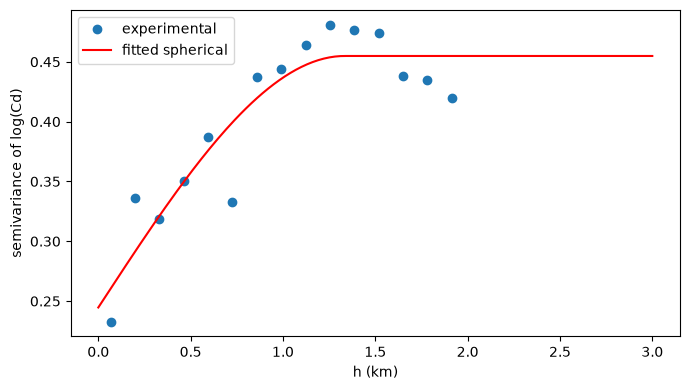

In [2]:
DATA = "../../../../Data/00_shared/data_geostatistics/"
jura = pd.read_csv(DATA + "jura_data.csv", index_col=0)
jura["logCd"] = np.log(jura["Cd"])
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
tr, te = next(sss.split(jura, jura["Landuse"]))
train, test = jura.iloc[tr].reset_index(drop=True), jura.iloc[te].reset_index(drop=True)
xy, xy_test = train[["Xloc", "Yloc"]].to_numpy(float), test[["Xloc", "Yloc"]].to_numpy(float)
z, z_test = train["logCd"].to_numpy(float), test["logCd"].to_numpy(float)

vg = Variogram(xy, z, model="spherical", n_lags=15, estimator="matheron", use_gpu=False).fit()
NUG, PSILL, RANGE = (float(v) for v in vg.fitted_params[:3])
TAU = NUG / PSILL
print(f"spherical variogram: nugget {NUG:.3f}, partial sill {PSILL:.3f}, range {RANGE:.2f} km  ->  relative nugget {TAU:.2f}")
hh = np.linspace(0, 3, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(vg.lags, vg.experimental, "o", label="experimental")
ax.plot(hh, vg(hh), "r-", label="fitted spherical")
ax.set_xlabel("h (km)")
ax.set_ylabel("semivariance of log(Cd)")
ax.legend()
plt.tight_layout()
plt.show()

***
## From a Fitted Variogram to a Bayesian Predictor

`BayesianKriging.from_variogram(vg)` builds a `ConjugateBayesianKriging` with the variogram's range and relative nugget and the reference prior. Its predictive mean should equal ordinary kriging with the same variogram, and its predictive scale should be the ordinary kriging variance with the sill replaced by the posterior estimate.

In [3]:
cbk = BayesianKriging.from_variogram(vg).fit(xy, z)
print(type(cbk).__name__, "| range", cbk.range_grid, "| nugget ratio", np.round(cbk.nugget_grid, 3))
c = cbk._comps[0]
print(f"posterior: beta* = {c['beta'][0]:.3f}, S^2 = {c['s2']:.3f} (fitted partial sill {PSILL:.3f}), dof = {c['dof']:.0f}")

ok = OrdinaryKriging(vg, use_gpu=False).fit(xy, z)
ok_mean, ok_se = ok.predict(xy_test, return_variance=True)
c_mean, c_sd = cbk.predict(xy_test, return_std=True, signal=False)
loc, scale, dof = cbk._component_predictions(xy_test, signal=False)
record("conjugate mean == ordinary kriging", "PASS" if np.allclose(c_mean, ok_mean, atol=1e-4) else "FAIL",
       f"max |diff| {np.abs(c_mean - ok_mean).max():.1e}")
ratio = (scale[0] ** 2 / c["s2"]) / (ok_se ** 2 / (NUG + PSILL) * (1 + TAU))
print(f"(Student-t scale^2 / S^2) / (OK variance / sill, observation scale): mean {ratio.mean():.4f}")

ConjugateBayesianKriging | range [1.33409093] | nugget ratio [1.164]
posterior: beta* = 0.071, S^2 = 0.213 (fitted partial sill 0.210), dof = 250


✅ [PASS] conjugate mean == ordinary kriging  max |diff| 9.5e-09
(Student-t scale^2 / S^2) / (OK variance / sill, observation scale): mean 1.0000


Both identities hold exactly:

* **Location.** The predictive mean equals ordinary kriging to $10^{-8}$.
* **Scale.** Student-t scale² / $S^2$ equals the ordinary kriging variance divided by the partial sill (ratio 1.0000).

The conjugate model *is* ordinary kriging, with two changes:

* the sill is estimated from the data in the same pass, $S^2 = 0.213$ against the fitted 0.210;
* the distribution is a Student-t with $n - 1 = 250$ degrees of freedom.

With 251 samples the t is practically Gaussian, so the intervals are the same. The next section shows when they differ.

***
## Small Samples: Why the Student-t Matters

With 251 samples the Student-t has 250 degrees of freedom and is a Gaussian. Its value shows with **few** samples. The experiment repeats, 60 times for each sample size $n \in \{8, 12, 20, 40, 80, 160\}$:

1. draw $n$ random training sites from all 359;
2. predict 100 other random sites with the variogram fixed (range and relative nugget from the full data set; only the sill is estimated);
3. score the 90% intervals of three predictors:
    * **conjugate Bayesian:** Student-t with $n - 1$ degrees of freedom and scale from $S^2$;
    * **plug-in Gaussian:** the *same* location and scale, but Gaussian quantiles, which is what a kriging analysis with an estimated sill reports;
    * **oracle Gaussian:** Gaussian with the sill estimated from all 359 samples, which no real analysis has.

360 fits in 0.5 s


,dof,coverage: conjugate t,coverage: plug-in Gaussian,coverage: oracle Gaussian,width: t,width: Gaussian,t / Gaussian width
n,,,,,,,
8,7,0.902,0.864,0.895,2.663,2.312,1.152
12,11,0.903,0.876,0.902,2.362,2.163,1.092
20,19,0.913,0.899,0.905,2.283,2.172,1.051
40,39,0.916,0.910,0.902,2.157,2.106,1.024
80,79,0.914,0.910,0.910,1.987,1.964,1.012
160,159,0.905,0.904,0.904,1.887,1.876,1.006


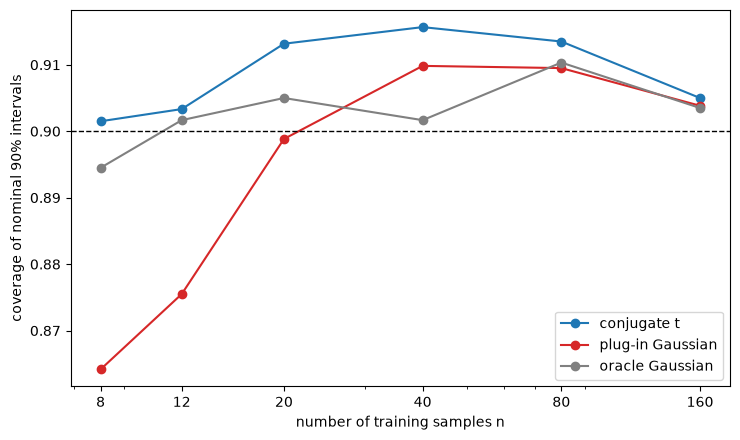

✅ [PASS] Student-t closer to 90% than plug-in Gaussian at n = 8  t 0.902, Gaussian 0.864


In [4]:
all_xy = jura[["Xloc", "Yloc"]].to_numpy(float)
all_z = jura["logCd"].to_numpy(float)
vg_all = Variogram(all_xy, all_z, model="spherical", n_lags=15, estimator="matheron", use_gpu=False).fit()
nug_a, psill_a, range_a = (float(v) for v in vg_all.fitted_params[:3])
tau_a = nug_a / psill_a
oracle_s2 = ConjugateBayesianKriging("spherical", range_=range_a, nugget_ratio=tau_a).fit(all_xy, all_z)._comps[0]["s2"]

rng = np.random.default_rng(0)
rows = []
t0 = time.perf_counter()
for n in [8, 12, 20, 40, 80, 160]:
    cov_t, cov_g, cov_o, w_t, w_g = [], [], [], [], []
    for rep in range(60):
        idx = rng.permutation(len(all_z))
        trn, tst = idx[:n], idx[n:n + 100]
        m = ConjugateBayesianKriging("spherical", range_=range_a, nugget_ratio=tau_a).fit(all_xy[trn], all_z[trn])
        loc_, sc_, df_ = m._component_predictions(all_xy[tst], signal=False)
        loc_, sc_, df_ = loc_[0], sc_[0], df_[0]
        unit = sc_ / np.sqrt(m._comps[0]["s2"])
        yt = all_z[tst]
        qt, qg = stats.t.ppf(0.95, df_), stats.norm.ppf(0.95)
        cov_t.append(np.mean(np.abs(yt - loc_) <= qt * sc_))
        cov_g.append(np.mean(np.abs(yt - loc_) <= qg * sc_))
        cov_o.append(np.mean(np.abs(yt - loc_) <= qg * unit * np.sqrt(oracle_s2)))
        w_t.append(np.mean(2 * qt * sc_))
        w_g.append(np.mean(2 * qg * sc_))
    rows.append({"n": n, "dof": n - 1, "coverage: conjugate t": np.mean(cov_t), "coverage: plug-in Gaussian": np.mean(cov_g),
                 "coverage: oracle Gaussian": np.mean(cov_o), "width: t": np.mean(w_t), "width: Gaussian": np.mean(w_g),
                 "t / Gaussian width": np.mean(w_t) / np.mean(w_g)})
small = pd.DataFrame(rows).set_index("n")
print(f"{6 * 60} fits in {time.perf_counter() - t0:.1f} s")
display(small.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for col, c_ in [("coverage: conjugate t", "tab:blue"), ("coverage: plug-in Gaussian", "tab:red"), ("coverage: oracle Gaussian", "0.5")]:
    ax.plot(small.index, small[col], "o-", c=c_, label=col.replace("coverage: ", ""))
ax.axhline(0.9, color="k", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xticks(small.index, small.index)
ax.set_xlabel("number of training samples n")
ax.set_ylabel("coverage of nominal 90% intervals")
ax.legend()
plt.tight_layout()
plt.show()
record("Student-t closer to 90% than plug-in Gaussian at n = 8",
       "PASS" if abs(small.loc[8, "coverage: conjugate t"] - 0.9) < abs(small.loc[8, "coverage: plug-in Gaussian"] - 0.9) else "FAIL",
       f"t {small.loc[8, 'coverage: conjugate t']:.3f}, Gaussian {small.loc[8, 'coverage: plug-in Gaussian']:.3f}")

* **Few samples: the Student-t keeps its promise.** With 8 samples, the Student-t intervals cover 90.2% of the held-out values, while the Gaussian intervals with the same estimated sill cover only 86.4%. The t intervals are 15% wider at $n = 8$ and 9% wider at $n = 12$, and that extra width is exactly what is needed to account for estimating the sill from a handful of values.
* **More samples: the two converge.** From $n \approx 40$ the two agree within 1%, and the plug-in Gaussian is calibrated too.
* **The oracle.** The Gaussian with the sill from all 359 samples is calibrated at every $n$ (0.90-0.91): the problem at small $n$ is the *estimated* sill, and the Student-t accounts for it.
* **Wider intervals at small $n$.** All intervals are wider at small $n$ (2.7 against 1.9 log units), because prediction sites are farther from the few data.
* **Speed.** The 360 fits took half a second: the conjugate model is as cheap as kriging.

***
## Between Simple and Ordinary Kriging: the Trend Prior

With `trend=0`, the trend is a single mean $\beta_0$. A normal prior $\beta_0 \mid \sigma^2 \sim \mathcal{N}(m, \sigma^2 v_\beta)$ moves the predictor between two classical estimators:

* $v_\beta \to \infty$ gives **ordinary kriging**;
* $v_\beta \to 0$ gives **simple kriging** with mean $m$.

The prior mean here is $m = 0$ on the log scale, i.e. Cd = 1 mg/kg, a plausible regional value. The limits are checked against `OrdinaryKriging` and `SimpleKriging(mean=0)`, and the posterior mean of $\beta_0$ is traced along the way.

In [5]:
M0 = 0.0
sk = SimpleKriging(vg, mean=M0, use_gpu=False).fit(xy, z)
sk_mean = sk.predict(xy_test)
rows = []
for vb in [1e-8, 0.001, 0.01, 0.05, 0.2, 1.0, 10.0, 1e8]:
    m = ConjugateBayesianKriging("spherical", range_=RANGE, nugget_ratio=TAU,
                                 beta_prior=("normal", [M0], [[vb]])).fit(xy, z)
    pm, ps = m.predict(xy_test, return_std=True, signal=False)
    rows.append({"prior variance v_beta": vb, "posterior beta0": m._comps[0]["beta"][0],
                 "max |mean - SK|": np.abs(pm - sk_mean).max(), "max |mean - OK|": np.abs(pm - ok_mean).max(),
                 "mean predictive sd": ps.mean(), "test RMSE": np.sqrt(np.mean((pm - z_test) ** 2))})
limits = pd.DataFrame(rows).set_index("prior variance v_beta")
display(limits.round(4))
record("tiny prior variance reproduces simple kriging", "PASS" if limits.iloc[0]["max |mean - SK|"] < 1e-3 else "FAIL",
       f"max diff {limits.iloc[0]['max |mean - SK|']:.1e}")
record("huge prior variance reproduces ordinary kriging", "PASS" if limits.iloc[-1]["max |mean - OK|"] < 1e-3 else "FAIL",
       f"max diff {limits.iloc[-1]['max |mean - OK|']:.1e}")

,posterior beta0,max |mean - SK|,max |mean - OK|,mean predictive sd,test RMSE
prior variance v_beta,,,,,
1.000000e-08,0.0000,0.0000,0.0332,0.5638,0.5586
1.000000e-03,0.0011,0.0005,0.0327,0.5638,0.5586
1.000000e-02,0.0093,0.0044,0.0288,0.5638,0.5586
5.000000e-02,0.0305,0.0143,0.0189,0.5637,0.5586
2.000000e-01,0.0533,0.0250,0.0082,0.5637,0.5586
1.000000e+00,0.0664,0.0311,0.0021,0.5636,0.5586
1.000000e+01,0.0704,0.0330,0.0002,0.5636,0.5586
1.000000e+08,0.0708,0.0332,0.0000,0.5636,0.5586


✅ [PASS] tiny prior variance reproduces simple kriging  max diff 1.0e-08
✅ [PASS] huge prior variance reproduces ordinary kriging  max diff 9.4e-09


* **Both limits are exact:** $v_\beta = 10^{-8}$ reproduces `SimpleKriging(mean=0)` and $v_\beta = 10^{8}$ reproduces `OrdinaryKriging`, both to $10^{-8}$.
* **In between, the posterior mean of $\beta_0$** moves smoothly from the prior mean 0 to the GLS estimate 0.071, the predictions move with it, and the predictor is a compromise between simple and ordinary kriging (Omre, 1987).
* **With 251 samples the choice hardly matters here.** Predictions differ by at most 0.03 log units, and the test RMSE and mean sd do not change in the fourth decimal. The prior mean (0) is close to the data's (0.07), and many data pin down $\beta_0$. A trend prior matters when the data are few, or when the prior mean is far from the data (Section 9).

***
## Trend Uncertainty Away from the Data

The trend term $\mathbf{g}^\top\mathbf{V}_\beta^*\mathbf{g}$ in the predictive variance grows as the prediction point moves away from where the trend was estimated. Along an east-west transect through the study area, extended 3 km beyond it on both sides, the predictive sd is compared for a constant (`trend=0`), linear (`trend=1`) and quadratic (`trend=2`) trend. The test-set accuracy of the three is also compared.

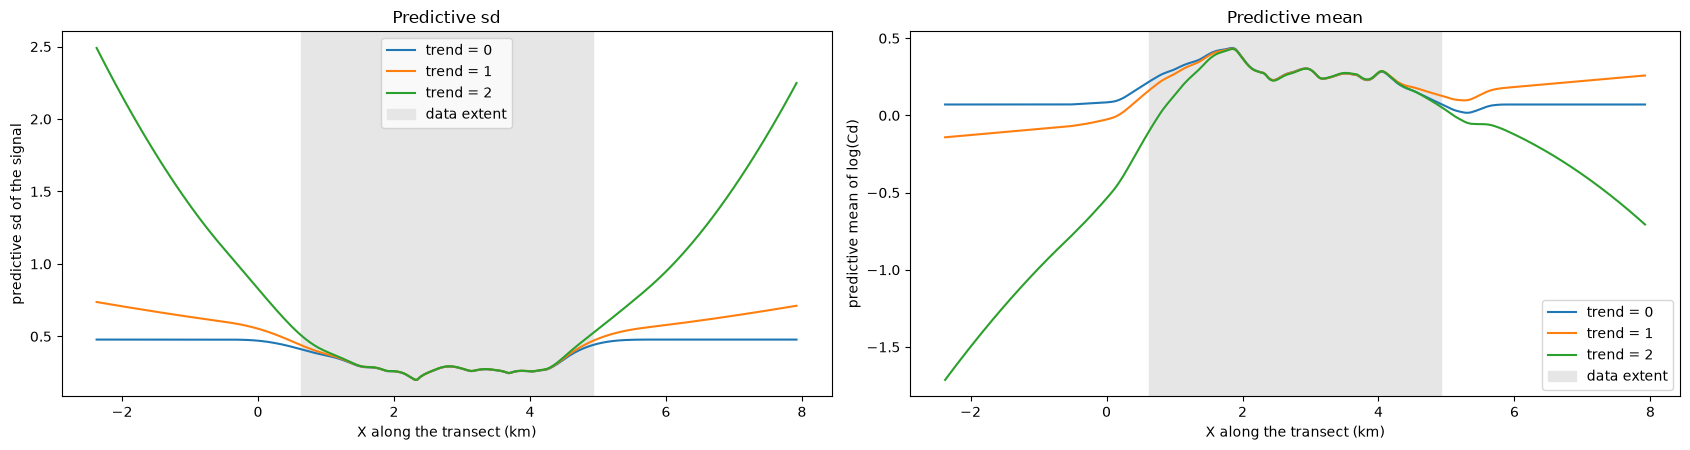

,p (trend terms),test RMSE,coverage 90%,mean sd
trend degree,,,,
0,1,0.559,0.926,0.565
1,3,0.558,0.926,0.567
2,6,0.562,0.907,0.569


In [6]:
tx = np.linspace(xy[:, 0].min() - 3, xy[:, 0].max() + 3, 300)
transect = np.column_stack([tx, np.full_like(tx, np.median(xy[:, 1]))])
fig, axes = plt.subplots(1, 2, figsize=(17, 4.6))
rows = []
for deg, c_ in [(0, "tab:blue"), (1, "tab:orange"), (2, "tab:green")]:
    m = ConjugateBayesianKriging("spherical", range_=RANGE, nugget_ratio=TAU, trend=deg).fit(xy, z)
    mu_, sd_ = m.predict(transect, return_std=True)
    axes[0].plot(tx, sd_, c=c_, label=f"trend = {deg}")
    axes[1].plot(tx, mu_, c=c_, label=f"trend = {deg}")
    pm, ps = m.predict(xy_test, return_std=True, signal=False)
    q = m.predict_quantiles(xy_test, [0.05, 0.95], signal=False)
    rows.append({"trend degree": deg, "p (trend terms)": len(m.beta_names_), "test RMSE": np.sqrt(np.mean((pm - z_test) ** 2)),
                 "coverage 90%": np.mean((z_test >= q[:, 0]) & (z_test <= q[:, 1])), "mean sd": ps.mean()})
for ax in axes:
    ax.axvspan(xy[:, 0].min(), xy[:, 0].max(), color="0.9", zorder=0, label="data extent")
    ax.set_xlabel("X along the transect (km)")
    ax.legend()
axes[0].set_ylabel("predictive sd of the signal")
axes[0].set_title("Predictive sd")
axes[1].set_ylabel("predictive mean of log(Cd)")
axes[1].set_title("Predictive mean")
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("trend degree").round(3)

* **Inside the study area**, the three trend models give nearly the same predictive sd: test RMSE 0.558-0.562, coverage 0.91-0.93. A polynomial trend adds nothing to these data, and the quadratic model's six coefficients cost a little coverage.
* **Outside the data**, they differ sharply:
    * with a constant trend, the sd levels off at the sill, because the prediction reverts to the estimated mean;
    * with a linear trend, it grows linearly with distance;
    * with a quadratic trend, it grows quadratically.

  The trend term $\mathbf{g}^\top\mathbf{V}_\beta^*\mathbf{g}$ measures how far the trend is being extrapolated, and the predictive means diverge accordingly. Plug-in universal kriging includes the same term in its variance, but a polynomial trend should never be extrapolated far without strong reasons.

***
## Informative Priors from an Earlier Survey

A common situation: a **new survey** has only a few samples, but an **earlier survey** nearby gives a fair idea of the mean and variability. The Jura is split at its median x coordinate:

* the **western** samples play the earlier survey;
* in the **east**, 15 sites are drawn as the new survey, and the remaining eastern sites are predicted.

The earlier survey's posterior becomes the prior for the new one:

* **trend:** $\mathbf{m}$ = its $\beta^*$, and $\mathbf{V}_\beta$ = its $\mathbf{V}_\beta^*$ inflated 5× as a discount, because two areas are not identical;
* **variance:** $n_0 = 10$ prior "observations" of the variance at its $S^2$.

Three priors are compared on 40 random draws of the 15 eastern sites:

* the reference prior;
* the earlier survey's prior;
* a deliberately **wrong**, confident prior: a mean 1.5 log units too high with a small $\mathbf{V}_\beta$.

In [7]:
west = jura["Xloc"] < jura["Xloc"].median()
xy_w, z_w = jura.loc[west, ["Xloc", "Yloc"]].to_numpy(float), jura.loc[west, "logCd"].to_numpy(float)
xy_e, z_e = jura.loc[~west, ["Xloc", "Yloc"]].to_numpy(float), jura.loc[~west, "logCd"].to_numpy(float)
old = ConjugateBayesianKriging("spherical", range_=range_a, nugget_ratio=tau_a).fit(xy_w, z_w)._comps[0]
print(f"earlier survey (west, n = {len(z_w)}): beta* {old['beta'][0]:.3f}, S^2 {old['s2']:.3f};  "
      f"east mean log(Cd) {z_e.mean():.3f}, variance {z_e.var():.3f}")
priors = {
    "reference (flat, 1/sigma^2)": dict(),
    "earlier survey": dict(beta_prior=("normal", old["beta"], 5 * old["Vbeta"]),
                           sigma2_prior=("scaled_inv_chi2", 10.0, old["s2"])),
    "wrong and confident": dict(beta_prior=("normal", old["beta"] + 1.5, 0.01 * np.eye(1)),
                                sigma2_prior=("scaled_inv_chi2", 10.0, old["s2"])),
}
rng = np.random.default_rng(5)
res = {k: {"rmse": [], "cover": [], "width": [], "beta": []} for k in priors}
for rep in range(40):
    idx = rng.permutation(len(z_e))
    trn, tst = idx[:15], idx[15:]
    for k, kw in priors.items():
        m = ConjugateBayesianKriging("spherical", range_=range_a, nugget_ratio=tau_a, **kw).fit(xy_e[trn], z_e[trn])
        pm = m.predict(xy_e[tst], signal=False)
        q = m.predict_quantiles(xy_e[tst], [0.05, 0.95], signal=False)
        res[k]["rmse"].append(np.sqrt(np.mean((pm - z_e[tst]) ** 2)))
        res[k]["cover"].append(np.mean((z_e[tst] >= q[:, 0]) & (z_e[tst] <= q[:, 1])))
        res[k]["width"].append(np.mean(q[:, 1] - q[:, 0]))
        res[k]["beta"].append(m._comps[0]["beta"][0])
prior_tab = pd.DataFrame({k: {"RMSE": np.mean(v["rmse"]), "coverage 90%": np.mean(v["cover"]),
                              "width 90%": np.mean(v["width"]), "posterior beta0 (mean)": np.mean(v["beta"]),
                              "posterior beta0 (sd over draws)": np.std(v["beta"])} for k, v in res.items()}).T
display(prior_tab.round(3))
record("earlier-survey prior beats the reference prior with 15 samples (RMSE)",
       "PASS" if prior_tab.loc["earlier survey", "RMSE"] < prior_tab.loc["reference (flat, 1/sigma^2)", "RMSE"] else "FAIL",
       f"{prior_tab.loc['reference (flat, 1/sigma^2)', 'RMSE']:.3f} -> {prior_tab.loc['earlier survey', 'RMSE']:.3f}")

earlier survey (west, n = 179): beta* -0.023, S^2 0.243;  east mean log(Cd) 0.211, variance 0.305


,RMSE,coverage 90%,width 90%,posterior beta0 (mean),posterior beta0 (sd over draws)
"reference (flat, 1/sigma^2)",0.583,0.897,1.965,0.217,0.141
earlier survey,0.578,0.930,2.057,0.140,0.095
wrong and confident,0.887,0.931,3.127,1.423,0.008


✅ [PASS] earlier-survey prior beats the reference prior with 15 samples (RMSE)  0.583 -> 0.578


The east and the west differ: the earlier survey's mean is −0.02 in log(Cd), the east's 0.21. That is a realistic test of borrowing information.

* **The earlier-survey prior helps, modestly.** The posterior of $\beta_0$ varies less between draws of the 15 sites (sd 0.095 against 0.141), RMSE improves slightly (0.578 against 0.583), and coverage rises to 0.93. The prior pulls $\beta_0$ toward the west's lower mean (0.14 against 0.22), the cost of borrowing from a different area. The 5× discount on $\mathbf{V}_\beta$ keeps that pull moderate.
* **The wrong, confident prior hurts the predictions** (RMSE 0.89), since it fixes $\beta_0$ at 1.42, far from the data. **Yet its intervals still cover 93%.** In the conjugate model, a conflict between prior and data inflates $Q$ and with it the posterior sill $S^{*2}$, so the intervals widen (3.1 against 2.0 log units). The model signals its own conflict, and it is worth checking: a posterior sill far above the prior's $s_0^2$, or $\beta^*$ far from the GLS estimate, means the prior and the data disagree.

***
## The Weak Point: a Fixed Range

The conjugate model is only as good as the fixed range and nugget. The same predictor is run on the 70/30 split with the range multiplied by 0.25 to 4 (the relative nugget kept), and compared with `BayesianKriging`, which averages over a grid of ranges and nugget ratios instead of fixing them.

In [8]:
rows = []
for f in [0.25, 0.5, 1.0, 2.0, 4.0]:
    m = ConjugateBayesianKriging("spherical", range_=RANGE * f, nugget_ratio=TAU).fit(xy, z)
    pm = m.predict(xy_test, signal=False)
    q = m.predict_quantiles(xy_test, [0.05, 0.95], signal=False)
    rows.append({"model": f"conjugate, range x {f}", "range (km)": RANGE * f, "test RMSE": np.sqrt(np.mean((pm - z_test) ** 2)),
                 "coverage 90%": np.mean((z_test >= q[:, 0]) & (z_test <= q[:, 1])), "width 90%": np.mean(q[:, 1] - q[:, 0])})
bk = BayesianKriging("spherical", range_grid=np.geomspace(0.1, 4, 25), nugget_grid=[0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5]).fit(xy, z)
pm = bk.predict(xy_test, signal=False)
q = bk.predict_quantiles(xy_test, [0.05, 0.95], signal=False)
rows.append({"model": "BayesianKriging (grid over range and nugget)", "range (km)": float((bk.posterior_.weight * bk.posterior_.range).sum()),
             "test RMSE": np.sqrt(np.mean((pm - z_test) ** 2)), "coverage 90%": np.mean((z_test >= q[:, 0]) & (z_test <= q[:, 1])),
             "width 90%": np.mean(q[:, 1] - q[:, 0])})
range_tab = pd.DataFrame(rows).set_index("model")
range_tab.round(3)

,range (km),test RMSE,coverage 90%,width 90%
model,,,,
"conjugate, range x 0.25",0.334,0.569,0.917,1.922
"conjugate, range x 0.5",0.667,0.553,0.944,1.877
"conjugate, range x 1.0",1.334,0.559,0.926,1.857
"conjugate, range x 2.0",2.668,0.572,0.907,1.890
"conjugate, range x 4.0",5.336,0.591,0.907,1.941
BayesianKriging (grid over range and nugget),0.485,0.556,0.935,1.899


* **The predictions are fairly robust to the fixed range.** Halving or doubling the range changes test RMSE by about 0.01, and coverage stays between 0.91 and 0.94. Even a 4× error costs only 0.03 in RMSE.
* **But nothing in the conjugate output warns about a wrong range.** The intervals are about equally wide whatever the range: the conjugate model reports uncertainty *given* the range.
* **`BayesianKriging`**, which averages over the range and the nugget (posterior mean range 0.49 km, much shorter than the fitted 1.33 km), matches the best fixed range on RMSE (0.556) and coverage (0.935) without having to know it.

With this many well-spread data, the fixed-range model loses little. With sparse data, or when the variogram fit is uncertain, the difference grows, and that is the case for `BayesianKriging`.

***
## Maps

On a 100 m version of the Jura grid (1,540 nodes), the conjugate model with the fitted variogram gives exact Student-t summaries at every node:

* the predictive median of log(Cd), back-transformed as exp(median), which is the median Cd;
* the width of the 90% interval;
* $P(\text{Cd} > 0.8 \text{ mg/kg})$.

1540 nodes in 0.11 s


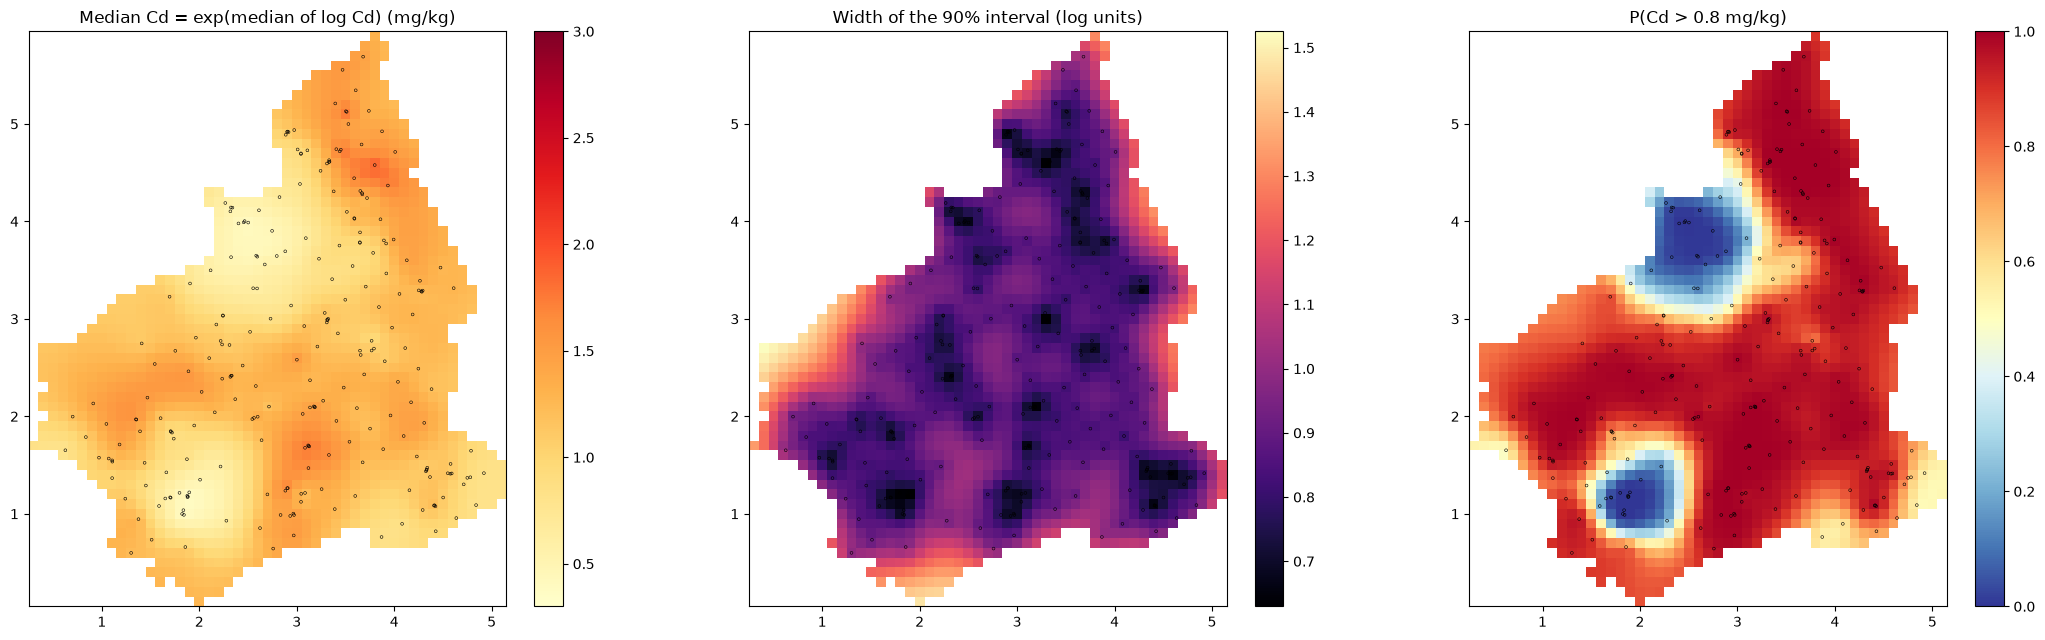

In [9]:
grid_df = pd.read_csv(DATA + "jura_grid.csv", index_col=0)
g = grid_df[["Xloc", "Yloc"]].to_numpy(float)
i50 = np.rint((g[:, 0] - g[:, 0].min()) / 0.05).astype(int)
j50 = np.rint((g[:, 1] - g[:, 1].min()) / 0.05).astype(int)
grid = g[(i50 % 2 == 0) & (j50 % 2 == 0)]
gi = np.rint((grid[:, 0] - grid[:, 0].min()) / 0.1).astype(int)
gj = np.rint((grid[:, 1] - grid[:, 1].min()) / 0.1).astype(int)
EXT = [grid[:, 0].min() - 0.05, grid[:, 0].max() + 0.05, grid[:, 1].min() - 0.05, grid[:, 1].max() + 0.05]
t0 = time.perf_counter()
qg = cbk.predict_quantiles(grid, [0.05, 0.5, 0.95])
pg = cbk.predict_proba(grid, np.log(0.8))
print(f"{len(grid)} nodes in {time.perf_counter() - t0:.2f} s")
fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
for ax, (v, title, cm, lo_, hi_) in zip(axes, [
        (np.exp(qg[:, 1]), "Median Cd = exp(median of log Cd) (mg/kg)", "YlOrRd", 0.3, 3),
        (qg[:, 2] - qg[:, 0], "Width of the 90% interval (log units)", "magma", None, None),
        (pg, "P(Cd > 0.8 mg/kg)", "RdYlBu_r", 0, 1)]):
    img = np.full((gj.max() + 1, gi.max() + 1), np.nan)
    img[gj, gi] = v
    im = ax.imshow(img, origin="lower", extent=EXT, cmap=cm, vmin=lo_, vmax=hi_, interpolation="nearest")
    ax.scatter(xy[:, 0], xy[:, 1], s=4, facecolors="none", edgecolors="k", linewidths=0.4)
    ax.set_title(title)
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

* **Exact and fast.** The Student-t summaries are computed exactly at 1,540 nodes in about 0.1 s.
* **The median Cd map** shows the smooth ordinary-kriging pattern.
* **Interval width.** The 90% interval width is smallest at the samples and largest in gaps and along the edges.
* **Exceedance.** $P(\text{Cd} > 0.8)$ is high over most of the area (most samples exceed the guide value), and drops only where predicted cadmium is clearly low.

***
## Summary and Conclusions

In [10]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,conjugate mean == ordinary kriging,PASS,max |diff| 9.5e-09
1,Student-t closer to 90% than plug-in Gaussian ...,PASS,"t 0.902, Gaussian 0.864"
2,tiny prior variance reproduces simple kriging,PASS,max diff 1.0e-08
3,huge prior variance reproduces ordinary kriging,PASS,max diff 9.4e-09
4,earlier-survey prior beats the reference prior...,PASS,0.583 -> 0.578


- **`ConjugateBayesianKriging`** fixes the correlation (range, model, nugget ratio) and integrates the trend and sill out exactly. Its predictive mean equals ordinary (or universal) kriging, and its predictive distribution is a Student-t with the kriging variance scaled by the posterior sill: both identities hold to $10^{-8}$ on the Jura data.
- **With few samples, the Student-t matters.** With 8 samples its 90% intervals covered 90.2% of held-out values, against 86.4% for Gaussian intervals with the same estimated sill. From about 40 samples the two agree.
- **The trend prior** spans the classical estimators: a tiny prior variance reproduces simple kriging, a huge one ordinary kriging, both exactly, with compromises in between.
- **Trend uncertainty** is small inside the data but grows fast when a linear or quadratic trend is extrapolated.
- **Informative priors** from an earlier survey reduced the spread of the estimated mean with only 15 new samples. A wrong, confident prior gave poor predictions, but the conjugate model widened its intervals in response to the prior-data conflict.
- **The fixed range** is the model's blind spot. Here the predictions were robust to it, and `BayesianKriging`, which averages over the range, matched the best fixed choice without knowing it.

### When to use which

| Situation | Choice |
|---|---|
| A trusted variogram (from a large earlier survey, or a well-established model) | `ConjugateBayesianKriging` / `from_variogram`: exact, fast, Student-t intervals |
| Few samples | the conjugate model at least; its t intervals stay calibrated where Gaussian plug-in intervals do not |
| Prior knowledge of the mean or the variability | `beta_prior=("normal", m, Vb)` and `sigma2_prior=("scaled_inv_chi2", n0, s0sq)`, discounted; check for prior-data conflict |
| A known mean | a small `Vb` reproduces simple kriging with Student-t intervals |
| A polynomial trend | expect wide intervals outside the data, where the trend is extrapolated |
| Range or nugget uncertain | `BayesianKriging`, which averages over them |

***
## References

| Reference | Used for |
|---|---|
| Kitanidis, P.K. (1986). Parameter uncertainty in estimation of spatial functions: Bayesian analysis. *Water Resources Research* 22, 499-507. | Conjugate Bayesian kriging |
| Handcock, M.S. & Stein, M.L. (1993). A Bayesian analysis of kriging. *Technometrics* 35, 403-410. | Student-t predictive |
| Omre, H. (1987). Bayesian kriging: merging observations and qualified guesses in kriging. *Mathematical Geology* 19, 25-39. | Informative trend priors between simple and universal kriging |
| Diggle, P.J. & Ribeiro, P.J. (2007). *Model-based Geostatistics*. Springer. | Normal-inverse-gamma prior, prediction |
| Gelman, A., Carlin, J.B., Stern, H.S., Dunson, D.B., Vehtari, A. & Rubin, D.B. (2013). *Bayesian Data Analysis*, 3rd ed. CRC Press. | Conjugate normal linear model |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Jura data |